In [2]:
import sys
from pathlib import Path

# Configuración de rutas adaptada para Jupyter Notebook
ruta_actual = Path().resolve() 
ruta_src = ruta_actual.parent / "src"

# Solo lo añadimos si no está ya en sys.path para evitar duplicados al correr la celda varias veces
if str(ruta_src) not in sys.path:
    sys.path.append(str(ruta_src))

import pygarg.dung.solver

def test_punto_2_maximales():
    # 1. Los 4 nodos de la Fig. 4 del artículo
    args = ['a', 'b', 'c', 'd']
    
    # 2. Los ataques que generan las facetas
    atts = [('c', 'a'), ('d', 'c'), ('b', 'd')]
    
    # 3. Pedimos a pygarg la semántica CF
    print("Calculando semántica 'CF' con pygarg y filtrando maximales...\n")
    extensiones_cf = list(pygarg.dung.solver.extension_enumeration(args, atts, 'CF'))
    
    # 4. Convertimos a sets descartando el conjunto vacío
    facetas_todas = [set(ext) for ext in extensiones_cf if ext]
    
    # 5. Aplicamos el filtro estricto de maximalidad
    # Solo nos quedamos con 'f' si NO es subconjunto estricto (<) de ningún otro 'g'
    facetas = [f for f in facetas_todas if not any(f < g for g in facetas_todas if f != g)]
    
    print(f"Total de conjuntos maximales devueltos: {len(facetas)}\n")
    for f in facetas:
        print(f)

# Llamada directa a la función
test_punto_2_maximales()

Calculando semántica 'CF' con pygarg y filtrando maximales...

Total de conjuntos maximales devueltos: 3

{'b', 'c'}
{'a', 'b'}
{'a', 'd'}


In [3]:
import sys
from pathlib import Path

# Configuración de rutas adaptada para Jupyter Notebook
ruta_actual = Path().resolve() 
ruta_src = ruta_actual.parent / "src"

if str(ruta_src) not in sys.path:
    sys.path.append(str(ruta_src))

import pygarg.dung.solver

def test_reduccion_completa():
    # 1. Los 4 nodos de la Fig. 4 del artículo
    args = ['a', 'b', 'c', 'd']
    
    # 2. Los ataques que generan las facetas
    atts = [('c', 'a'), ('d', 'c'), ('b', 'd')]
    
    # 3. Pedimos a pygarg la semántica CF y filtramos maximales
    print("Calculando facetas (maximales)...\n")
    extensiones_cf = list(pygarg.dung.solver.extension_enumeration(args, atts, 'CF'))
    facetas_todas = [set(ext) for ext in extensiones_cf if ext]
    facetas = [f for f in facetas_todas if not any(f < g for g in facetas_todas if f != g)]
    
    # Ordenamos las facetas para que se asignen siempre en el mismo orden (X_1, X_2, ...)
    facetas_ordenadas = sorted([sorted(list(f)) for f in facetas])
    A_star = {f"X_{i+1}": set(faceta) for i, faceta in enumerate(facetas_ordenadas)}
    
    print("Meta-argumentos (Facetas):")
    for id_X, X in A_star.items():
        print(f"  {id_X}: {X}")
        
    # 4. Diccionarios de adyacencia ultrarrápidos
    out_adj = {arg: set() for arg in args}
    in_adj = {arg: set() for arg in args}
    for atacante, atacado in atts:
        out_adj[atacante].add(atacado)
        in_adj[atacado].add(atacante)

    R_star = []
    pesos_w = {}
    valoraciones_tau = {}
    
    # 5. Calcular la función de peso w(X, Y) y la relación de ataque R*
    for id_X, X in A_star.items():
        for id_Y, Y in A_star.items():
            if id_X == id_Y: 
                continue
            
            # Intersección entre los objetivos de ataque de X y los argumentos en Y
            atacantes = {x for x in X if not out_adj[x].isdisjoint(Y)}
            
            if atacantes:
                R_star.append((id_X, id_Y))
                pesos_w[(id_X, id_Y)] = len(atacantes) / len(X)

    # 6. Calcular la Fuerza Inicial / Valoración Base (Tau)
    for id_X, X in A_star.items():
        r_out = sum(len([tgt for tgt in out_adj[x] if tgt not in X]) for x in X)
        r_in = sum(len([src for src in in_adj[x] if src not in X]) for x in X)
        
        if (r_out + r_in) == 0:
            valoraciones_tau[id_X] = 0.5
        else:
            valoraciones_tau[id_X] = 0.5 * (((r_out - r_in) / (r_out + r_in)) + 1.0)

    # 7. Mostrar resultados
    print("\nAtaques entre meta-argumentos (R*) y sus Pesos (w):")
    for origen, destino in R_star:
        print(f"  {origen} -> {destino} | Peso w: {pesos_w[(origen, destino)]:.2f}")

    print("\nFuerza Inicial (Tau) de cada meta-argumento:")
    for id_X, tau in valoraciones_tau.items():
        print(f"  {id_X}: {tau:.3f}")

# Llamada directa a la función
test_reduccion_completa()

Calculando facetas (maximales)...

Meta-argumentos (Facetas):
  X_1: {'a', 'b'}
  X_2: {'a', 'd'}
  X_3: {'b', 'c'}

Ataques entre meta-argumentos (R*) y sus Pesos (w):
  X_1 -> X_2 | Peso w: 0.50
  X_2 -> X_3 | Peso w: 0.50
  X_3 -> X_1 | Peso w: 0.50
  X_3 -> X_2 | Peso w: 1.00

Fuerza Inicial (Tau) de cada meta-argumento:
  X_1: 0.500
  X_2: 0.333
  X_3: 0.667


In [4]:
import sys
import statistics
from pathlib import Path

# Configuración de rutas para Jupyter Notebook
ruta_actual = Path().resolve() 
ruta_src = ruta_actual.parent / "src"

if str(ruta_src) not in sys.path:
    sys.path.append(str(ruta_src))

import pygarg.dung.solver

def reduccion_hibrida_maximal(args, atts, umbral_manual=None):
    """
    Comprime un AF en un W-QBAF extrayendo los conjuntos CF maximales.
    Permite aplicar un umbral dinámico o fijo para filtrar ataques débiles.
    """
    # 1. Extraer semántica CF y filtrar subconjuntos propios para obtener las facetas reales
    extensiones_cf = list(pygarg.dung.solver.extension_enumeration(args, atts, 'CF'))
    facetas_todas = [set(ext) for ext in extensiones_cf if ext]
    facetas = [f for f in facetas_todas if not any(f < g for g in facetas_todas if f != g)]
    
    # Ordenamos para asegurar consistencia en los IDs
    facetas_ordenadas = sorted([sorted(list(f)) for f in facetas])
    A_star_inicial = {f"X_{i+1}": set(faceta) for i, faceta in enumerate(facetas_ordenadas)}
    
    # 2. Diccionarios de adyacencia
    out_adj = {arg: set() for arg in args}
    in_adj = {arg: set() for arg in args}
    for atacante, atacado in atts:
        out_adj[atacante].add(atacado)
        in_adj[atacado].add(atacante)

    pesos_brutos = {}
    
    # 3. Calcular todos los pesos teóricos w(X,Y)
    for id_X, X in A_star_inicial.items():
        for id_Y, Y in A_star_inicial.items():
            if id_X == id_Y: 
                continue
            
            atacantes = {x for x in X if not out_adj[x].isdisjoint(Y)}
            if atacantes:
                pesos_brutos[(id_X, id_Y)] = len(atacantes) / len(X)
                
    # 4. Determinar el umbral a aplicar
    if not pesos_brutos:
        umbral_aplicado = 0.0
    elif umbral_manual is not None:
        umbral_aplicado = umbral_manual
    else:
        umbral_aplicado = statistics.mean(pesos_brutos.values())
    
    # 5. Filtrar usando el umbral seleccionado
    R_star_filtrado = []
    pesos_w_finales = {}
    nodos_conectados = set()
    
    for (origen, destino), peso in pesos_brutos.items():
        if peso >= umbral_aplicado:
            R_star_filtrado.append((origen, destino))
            pesos_w_finales[(origen, destino)] = peso
            nodos_conectados.add(origen)
            nodos_conectados.add(destino)
            
    # Separamos los nodos aislados (invictos) de los conectados
    A_star_conectados = {id_X: X for id_X, X in A_star_inicial.items() if id_X in nodos_conectados}
    A_star_aislados = {id_X: X for id_X, X in A_star_inicial.items() if id_X not in nodos_conectados}
    
    # 6. Calcular la Valoración Base (Tau)
    valoraciones_tau = {}
    for id_X, X in A_star_conectados.items():
        r_out = sum(len([tgt for tgt in out_adj[x] if tgt not in X]) for x in X)
        r_in = sum(len([src for src in in_adj[x] if src not in X]) for x in X)
        
        if (r_out + r_in) == 0:
            valoraciones_tau[id_X] = 0.5
        else:
            valoraciones_tau[id_X] = 0.5 * (((r_out - r_in) / (r_out + r_in)) + 1.0)
            
    # Asignar tau = 0.5 a los aislados
    for id_X in A_star_aislados.keys():
        valoraciones_tau[id_X] = 0.5
            
    return A_star_conectados, A_star_aislados, R_star_filtrado, pesos_w_finales, valoraciones_tau, umbral_aplicado

def ejecutar_prueba():
    # Grafo proporcionado
    args = ['a0', 'a1', 'a2', 'a3', 'a4', 'a5', 'a6', 'a7', 'a8', 'a9']
    atts = [('a4', 'a2'), ('a1', 'a0'), ('a2', 'a0'), ('a2', 'a8'), 
            ('a5', 'a2'), ('a2', 'a9'), ('a2', 'a5'), ('a0', 'a3'), 
            ('a7', 'a2'), ('a6', 'a5')]
    
    print("=== PRUEBA 1: UMBRAL DINÁMICO (MEDIA) ===")
    conectados, aislados, R_star, pesos, tau, umbral_dyn = reduccion_hibrida_maximal(args, atts)
    imprimir_resultados(conectados, aislados, R_star, pesos, tau, umbral_dyn)
    
    print("\n=== PRUEBA 2: UMBRAL FIJO (0.20) ===")
    conectados_f, aislados_f, R_star_f, pesos_f, tau_f, umbral_fijo = reduccion_hibrida_maximal(args, atts, umbral_manual=0.20)
    imprimir_resultados(conectados_f, aislados_f, R_star_f, pesos_f, tau_f, umbral_fijo)

def imprimir_resultados(conectados, aislados, R_star, pesos, tau, umbral):
    print(f"Umbral aplicado: {umbral:.3f}")
    print(f"Meta-argumentos Conectados ({len(conectados)}):")
    for id_X, X in conectados.items():
        print(f"  {id_X}: {X} | Tau: {tau[id_X]:.3f}")
        
    print(f"Meta-argumentos Aislados ({len(aislados)}):")
    for id_X, X in aislados.items():
        print(f"  {id_X}: {X} | Tau: {tau[id_X]:.3f}")
        
    print(f"Ataques ({len(R_star)}):")
    for origen, destino in R_star:
        print(f"  {origen} -> {destino} | w: {pesos[(origen, destino)]:.2f}")

# Ejecutar la celda
ejecutar_prueba()


=== PRUEBA 1: UMBRAL DINÁMICO (MEDIA) ===
Umbral aplicado: 0.319
Meta-argumentos Conectados (4):
  X_1: {'a4', 'a8', 'a7', 'a5', 'a0', 'a9'} | Tau: 0.400
  X_2: {'a4', 'a8', 'a7', 'a6', 'a0', 'a9'} | Tau: 0.500
  X_3: {'a3', 'a2', 'a1', 'a6'} | Tau: 0.600
  X_4: {'a4', 'a8', 'a7', 'a3', 'a5', 'a1', 'a9'} | Tau: 0.444
Meta-argumentos Aislados (1):
  X_5: {'a4', 'a8', 'a7', 'a3', 'a6', 'a1', 'a9'} | Tau: 0.500
Ataques (7):
  X_1 -> X_3 | w: 0.67
  X_2 -> X_3 | w: 0.50
  X_2 -> X_4 | w: 0.33
  X_3 -> X_1 | w: 0.75
  X_3 -> X_2 | w: 0.50
  X_3 -> X_4 | w: 0.50
  X_4 -> X_3 | w: 0.43

=== PRUEBA 2: UMBRAL FIJO (0.20) ===
Umbral aplicado: 0.200
Meta-argumentos Conectados (5):
  X_1: {'a4', 'a8', 'a7', 'a5', 'a0', 'a9'} | Tau: 0.400
  X_2: {'a4', 'a8', 'a7', 'a6', 'a0', 'a9'} | Tau: 0.500
  X_3: {'a3', 'a2', 'a1', 'a6'} | Tau: 0.600
  X_4: {'a4', 'a8', 'a7', 'a3', 'a5', 'a1', 'a9'} | Tau: 0.444
  X_5: {'a4', 'a8', 'a7', 'a3', 'a6', 'a1', 'a9'} | Tau: 0.571
Meta-argumentos Aislados (0):
Ataque

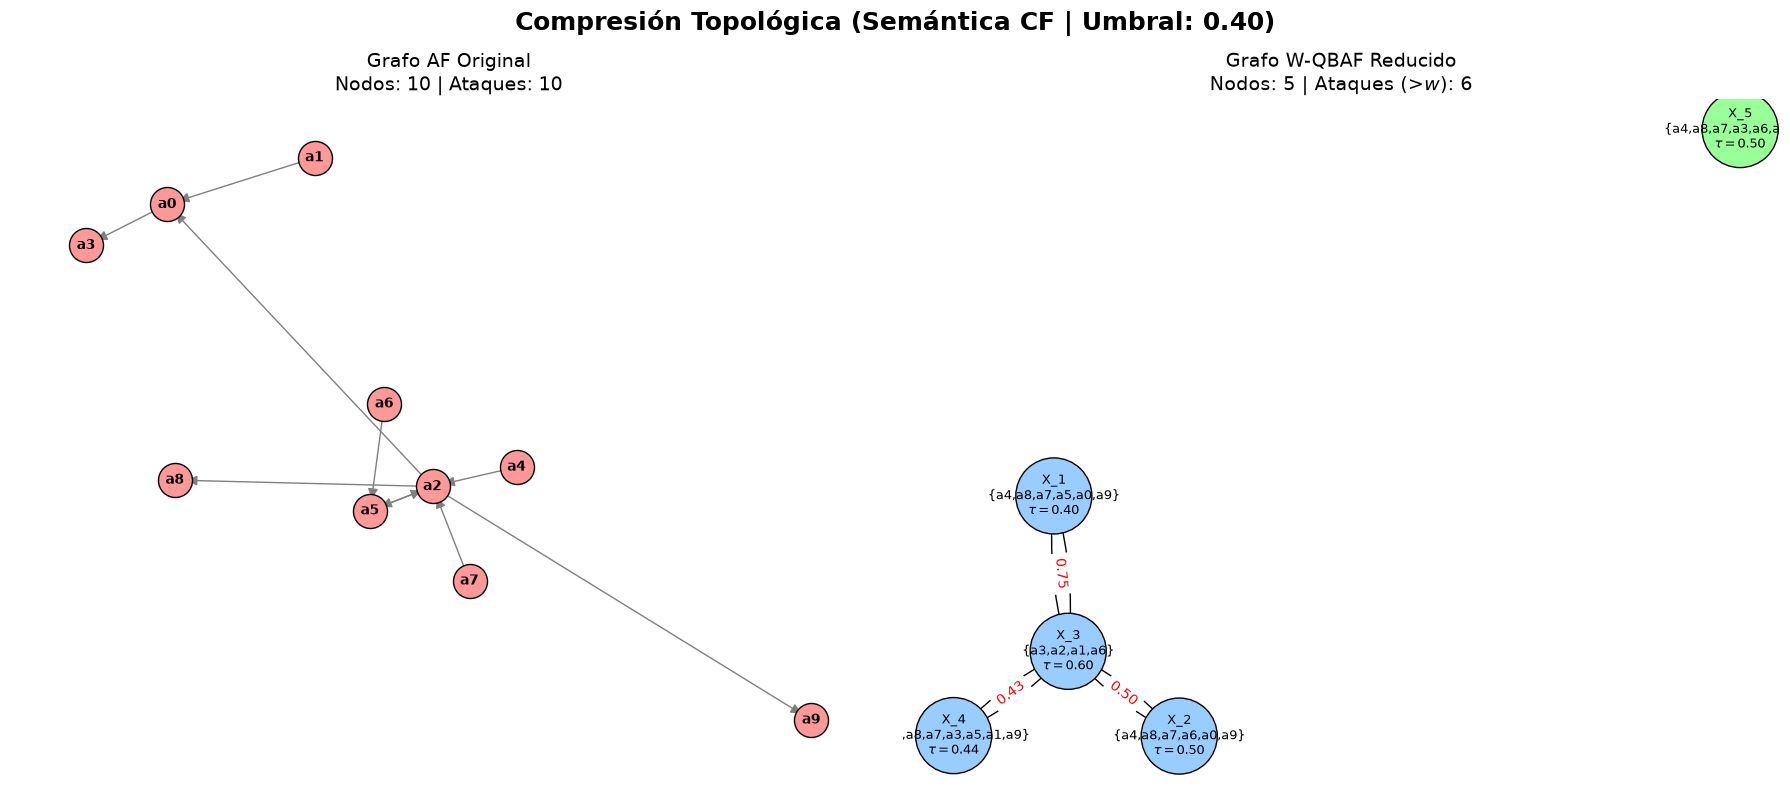

In [15]:
import sys
import statistics
import networkx as nx
import matplotlib.pyplot as plt
from pathlib import Path

# Configuración de rutas para importar pygarg
ruta_actual = Path().resolve()
ruta_src = ruta_actual.parent / "src"
if str(ruta_src) not in sys.path:
    sys.path.append(str(ruta_src))

import pygarg.dung.solver

def visualizar_reduccion_simplicial(args, atts, semantica='CF', umbral_manual=0.3):
    """
    Calcula la reducción W-QBAF y renderiza una comparativa visual
    usando networkx y matplotlib.
    """
    # ==========================================
    # 1. LÓGICA DE REDUCCIÓN (Semántica y Maximalidad)
    # ==========================================
    extensiones = list(pygarg.dung.solver.extension_enumeration(args, atts, semantica))
    
    # Descartar conjunto vacío y aplicar filtro estricto de maximalidad
    facetas_todas = [set(ext) for ext in extensiones if ext]
    facetas = [f for f in facetas_todas if not any(f < g for g in facetas_todas if f != g)]
    
    # Ordenar para mantener consistencia visual
    facetas_ordenadas = sorted([sorted(list(f)) for f in facetas])
    A_star_inicial = {f"X_{i+1}": set(faceta) for i, faceta in enumerate(facetas_ordenadas)}
    
    out_adj = {arg: set() for arg in args}
    in_adj = {arg: set() for arg in args}
    for atacante, atacado in atts:
        out_adj[atacante].add(atacado)
        in_adj[atacado].add(atacante)

    pesos_brutos = {}
    
    # Calcular pesos teóricos w(X,Y)
    for id_X, X in A_star_inicial.items():
        for id_Y, Y in A_star_inicial.items():
            if id_X == id_Y: continue
            
            atacantes = {x for x in X if not out_adj[x].isdisjoint(Y)}
            if atacantes:
                pesos_brutos[(id_X, id_Y)] = len(atacantes) / len(X)
                
    # Determinar y aplicar el umbral
    umbral_aplicado = umbral_manual if umbral_manual is not None else (statistics.mean(pesos_brutos.values()) if pesos_brutos else 0.0)
    
    R_star_filtrado = []
    pesos_w_finales = {}
    nodos_conectados = set()
    
    for (origen, destino), peso in pesos_brutos.items():
        if peso >= umbral_aplicado:
            R_star_filtrado.append((origen, destino))
            pesos_w_finales[(origen, destino)] = peso
            nodos_conectados.add(origen)
            nodos_conectados.add(destino)
            
    A_star_conectados = {id_X: X for id_X, X in A_star_inicial.items() if id_X in nodos_conectados}
    A_star_aislados = {id_X: X for id_X, X in A_star_inicial.items() if id_X not in nodos_conectados}
    
    valoraciones_tau = {}
    for id_X, X in A_star_conectados.items():
        r_out = sum(len([tgt for tgt in out_adj[x] if tgt not in X]) for x in X)
        r_in = sum(len([src for src in in_adj[x] if src not in X]) for x in X)
        valoraciones_tau[id_X] = 0.5 if (r_out + r_in) == 0 else 0.5 * (((r_out - r_in) / (r_out + r_in)) + 1.0)
        
    for id_X in A_star_aislados.keys():
        valoraciones_tau[id_X] = 0.5

    # ==========================================
    # 2. VISUALIZACIÓN GRÁFICA (Matplotlib + NetworkX)
    # ==========================================
    fig, axes = plt.subplots(1, 2, figsize=(18, 8))
    fig.suptitle(f"Compresión Topológica (Semántica {semantica} | Umbral: {umbral_aplicado:.2f})", fontsize=18, fontweight='bold')

    # --- GRAFO 1: AF ORIGINAL ---
    G_orig = nx.DiGraph()
    G_orig.add_nodes_from(args)
    G_orig.add_edges_from(atts)
    
    # Layout tipo resorte para mejor distribución
    pos_orig = nx.spring_layout(G_orig, seed=42)
    
    nx.draw_networkx_nodes(G_orig, pos_orig, ax=axes[0], node_color='#ff9999', node_size=600, edgecolors='black')
    nx.draw_networkx_labels(G_orig, pos_orig, ax=axes[0], font_size=10, font_weight='bold')
    nx.draw_networkx_edges(G_orig, pos_orig, ax=axes[0], arrowstyle='-|>', arrowsize=15, edge_color='gray')
    axes[0].set_title(f"Grafo AF Original\nNodos: {len(args)} | Ataques: {len(atts)}", fontsize=14)
    axes[0].axis('off')

    # --- GRAFO 2: W-QBAF REDUCIDO ---
    G_red = nx.DiGraph()
    
    # Preparamos las etiquetas de los nodos enriquecidas (ID + Argumentos + Tau)
    etiquetas_red = {}
    colores_nodos = []
    
    for id_X, X in A_star_conectados.items():
        G_red.add_node(id_X)
        args_str = "{" + ",".join(X) + "}"
        etiquetas_red[id_X] = f"{id_X}\n{args_str}\n$\\tau={valoraciones_tau[id_X]:.2f}$"
        colores_nodos.append('#99ccff') # Azul para conectados
        
    for id_X, X in A_star_aislados.items():
        G_red.add_node(id_X)
        args_str = "{" + ",".join(X) + "}"
        etiquetas_red[id_X] = f"{id_X}\n{args_str}\n$\\tau={valoraciones_tau[id_X]:.2f}$"
        colores_nodos.append('#99ff99') # Verde para aislados (invictos)

    G_red.add_edges_from(R_star_filtrado)
    
    # Dibujar el W-QBAF
    if len(G_red.nodes) > 0:
        pos_red = nx.spring_layout(G_red, seed=42)
        nx.draw_networkx_nodes(G_red, pos_red, ax=axes[1], node_color=colores_nodos, node_size=3000, edgecolors='black')
        nx.draw_networkx_labels(G_red, pos_red, labels=etiquetas_red, ax=axes[1], font_size=9)
        nx.draw_networkx_edges(G_red, pos_red, ax=axes[1], arrowstyle='-|>', arrowsize=20, edge_color='black', connectionstyle="arc3,rad=0.1")
        
        # Etiquetas de los pesos en las aristas
        etiquetas_aristas = {(u, v): f"{pesos_w_finales[(u, v)]:.2f}" for u, v in G_red.edges()}
        nx.draw_networkx_edge_labels(G_red, pos_red, edge_labels=etiquetas_aristas, ax=axes[1], font_size=10, font_color='red')
    
    nodos_red = len(A_star_conectados) + len(A_star_aislados)
    axes[1].set_title(f"Grafo W-QBAF Reducido\nNodos: {nodos_red} | Ataques (>$w$): {len(R_star_filtrado)}", fontsize=14)
    axes[1].axis('off')

    plt.tight_layout()
    plt.show()

# ==========================================
# 3. EJECUCIÓN DE PRUEBA (Grafo de 10 nodos)
# ==========================================
args_test = ['a0', 'a1', 'a2', 'a3', 'a4', 'a5', 'a6', 'a7', 'a8', 'a9']
atts_test = [('a4', 'a2'), ('a1', 'a0'), ('a2', 'a0'), ('a2', 'a8'), 
             ('a5', 'a2'), ('a2', 'a9'), ('a2', 'a5'), ('a0', 'a3'), 
             ('a7', 'a2'), ('a6', 'a5')]

# Llama a la función visualizadora (umbral_manual=None aplica el umbral dinámico)
visualizar_reduccion_simplicial(args_test, atts_test, semantica='CF', umbral_manual=0.4)



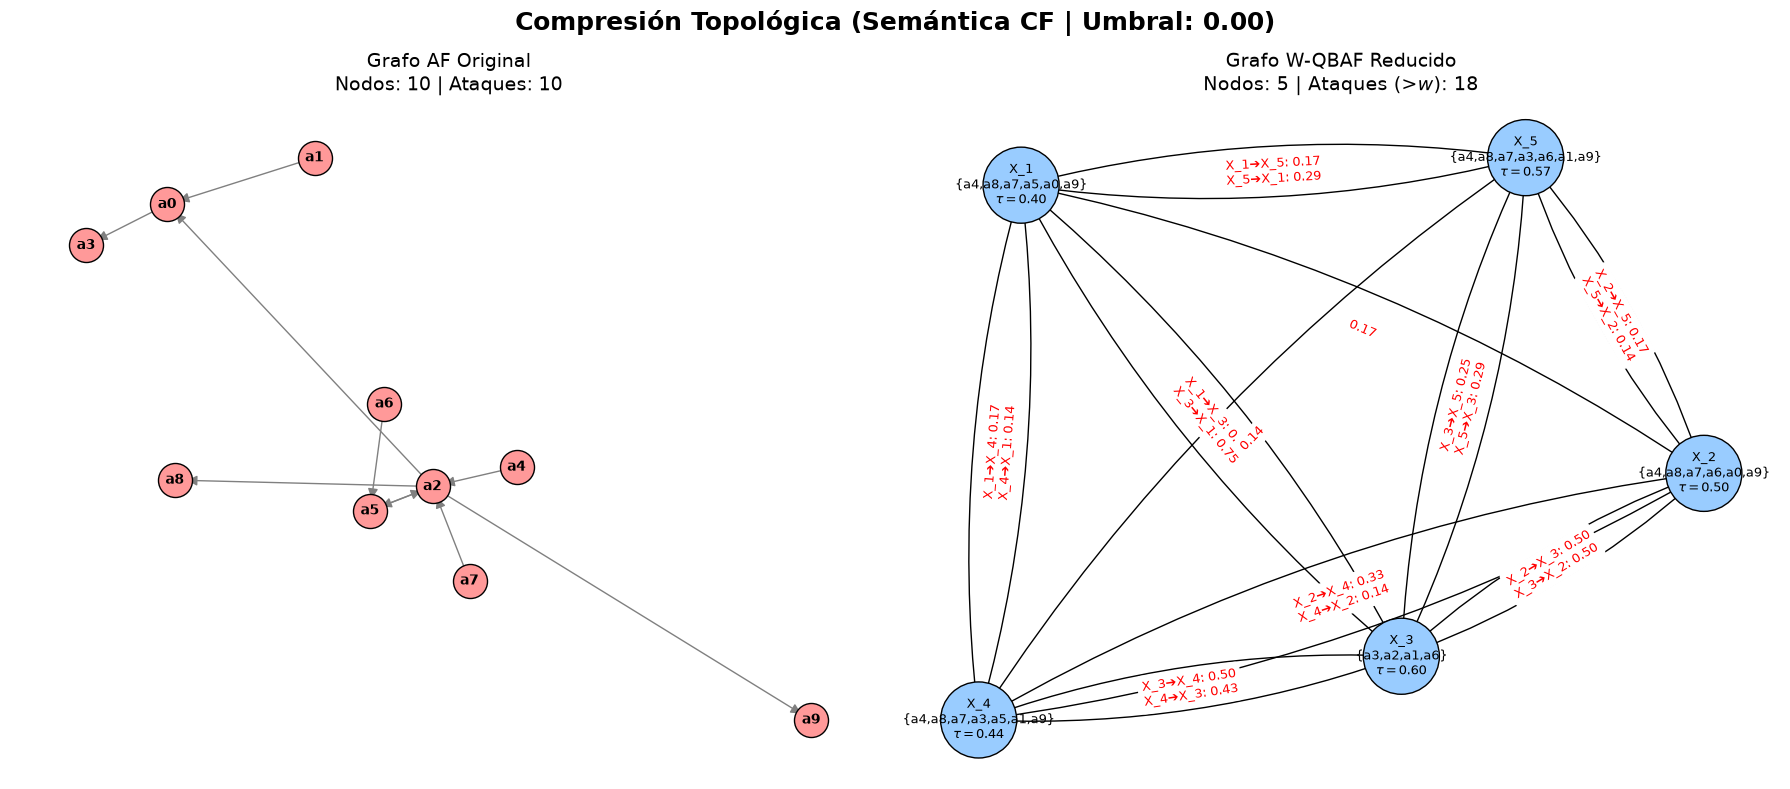

In [18]:
import sys
import statistics
import networkx as nx
import matplotlib.pyplot as plt
from pathlib import Path

# Configuración de rutas para importar pygarg
ruta_actual = Path().resolve()
ruta_src = ruta_actual.parent / "src"
if str(ruta_src) not in sys.path:
    sys.path.append(str(ruta_src))

import pygarg.dung.solver

def visualizar_reduccion_simplicial(args, atts, semantica='CO', umbral_manual=None):
    """
    Calcula la reducción W-QBAF y renderiza una comparativa visual
    usando networkx y matplotlib, corrigiendo la superposición de etiquetas.
    """
    # ==========================================
    # 1. LÓGICA DE REDUCCIÓN (Semántica y Maximalidad)
    # ==========================================
    extensiones = list(pygarg.dung.solver.extension_enumeration(args, atts, semantica))
    
    # Descartar conjunto vacío y aplicar filtro estricto de maximalidad
    facetas_todas = [set(ext) for ext in extensiones if ext]
    facetas = [f for f in facetas_todas if not any(f < g for g in facetas_todas if f != g)]
    
    # Ordenar para mantener consistencia visual
    facetas_ordenadas = sorted([sorted(list(f)) for f in facetas])
    A_star_inicial = {f"X_{i+1}": set(faceta) for i, faceta in enumerate(facetas_ordenadas)}
    
    out_adj = {arg: set() for arg in args}
    in_adj = {arg: set() for arg in args}
    for atacante, atacado in atts:
        out_adj[atacante].add(atacado)
        in_adj[atacado].add(atacante)

    pesos_brutos = {}
    
    # Calcular pesos teóricos w(X,Y)
    for id_X, X in A_star_inicial.items():
        for id_Y, Y in A_star_inicial.items():
            if id_X == id_Y: continue
            
            atacantes = {x for x in X if not out_adj[x].isdisjoint(Y)}
            if atacantes:
                pesos_brutos[(id_X, id_Y)] = len(atacantes) / len(X)
                
    # Determinar y aplicar el umbral
    umbral_aplicado = umbral_manual if umbral_manual is not None else (statistics.mean(pesos_brutos.values()) if pesos_brutos else 0.0)
    
    R_star_filtrado = []
    pesos_w_finales = {}
    nodos_conectados = set()
    
    for (origen, destino), peso in pesos_brutos.items():
        if peso >= umbral_aplicado:
            R_star_filtrado.append((origen, destino))
            pesos_w_finales[(origen, destino)] = peso
            nodos_conectados.add(origen)
            nodos_conectados.add(destino)
            
    A_star_conectados = {id_X: X for id_X, X in A_star_inicial.items() if id_X in nodos_conectados}
    A_star_aislados = {id_X: X for id_X, X in A_star_inicial.items() if id_X not in nodos_conectados}
    
    valoraciones_tau = {}
    for id_X, X in A_star_conectados.items():
        r_out = sum(len([tgt for tgt in out_adj[x] if tgt not in X]) for x in X)
        r_in = sum(len([src for src in in_adj[x] if src not in X]) for x in X)
        valoraciones_tau[id_X] = 0.5 if (r_out + r_in) == 0 else 0.5 * (((r_out - r_in) / (r_out + r_in)) + 1.0)
        
    for id_X in A_star_aislados.keys():
        valoraciones_tau[id_X] = 0.5

    # ==========================================
    # 2. VISUALIZACIÓN GRÁFICA (Matplotlib + NetworkX)
    # ==========================================
    fig, axes = plt.subplots(1, 2, figsize=(18, 8))
    fig.suptitle(f"Compresión Topológica (Semántica {semantica} | Umbral: {umbral_aplicado:.2f})", fontsize=18, fontweight='bold')

    # --- GRAFO 1: AF ORIGINAL ---
    G_orig = nx.DiGraph()
    G_orig.add_nodes_from(args)
    G_orig.add_edges_from(atts)
    
    pos_orig = nx.spring_layout(G_orig, seed=42)
    
    nx.draw_networkx_nodes(G_orig, pos_orig, ax=axes[0], node_color='#ff9999', node_size=600, edgecolors='black')
    nx.draw_networkx_labels(G_orig, pos_orig, ax=axes[0], font_size=10, font_weight='bold')
    nx.draw_networkx_edges(G_orig, pos_orig, ax=axes[0], arrowstyle='-|>', arrowsize=15, edge_color='gray')
    axes[0].set_title(f"Grafo AF Original\nNodos: {len(args)} | Ataques: {len(atts)}", fontsize=14)
    axes[0].axis('off')

    # --- GRAFO 2: W-QBAF REDUCIDO ---
    G_red = nx.DiGraph()
    
    etiquetas_red = {}
    colores_nodos = []
    
    for id_X, X in A_star_conectados.items():
        G_red.add_node(id_X)
        args_str = "{" + ",".join(X) + "}"
        etiquetas_red[id_X] = f"{id_X}\n{args_str}\n$\\tau={valoraciones_tau[id_X]:.2f}$"
        colores_nodos.append('#99ccff') 
        
    for id_X, X in A_star_aislados.items():
        G_red.add_node(id_X)
        args_str = "{" + ",".join(X) + "}"
        etiquetas_red[id_X] = f"{id_X}\n{args_str}\n$\\tau={valoraciones_tau[id_X]:.2f}$"
        colores_nodos.append('#99ff99') 

    G_red.add_edges_from(R_star_filtrado)
    
    if len(G_red.nodes) > 0:
        pos_red = nx.spring_layout(G_red, seed=42)
        nx.draw_networkx_nodes(G_red, pos_red, ax=axes[1], node_color=colores_nodos, node_size=3000, edgecolors='black')
        nx.draw_networkx_labels(G_red, pos_red, labels=etiquetas_red, ax=axes[1], font_size=9)
        nx.draw_networkx_edges(G_red, pos_red, ax=axes[1], arrowstyle='-|>', arrowsize=20, edge_color='black', connectionstyle="arc3,rad=0.1")
        
        # --- NUEVA LÓGICA PARA ETIQUETAS DE ARISTAS ---
        etiquetas_aristas = {}
        aristas_procesadas = set()
        
        for u, v in G_red.edges():
            if (u, v) in aristas_procesadas or (v, u) in aristas_procesadas:
                continue
                
            peso_ida = pesos_w_finales.get((u, v))
            peso_vuelta = pesos_w_finales.get((v, u))
            
            if peso_ida is not None and peso_vuelta is not None:
                # Ataque mutuo: separamos visualmente
                etiquetas_aristas[(u, v)] = f"{u}➔{v}: {peso_ida:.2f}\n{v}➔{u}: {peso_vuelta:.2f}"
            else:
                # Ataque unidireccional
                etiquetas_aristas[(u, v)] = f"{peso_ida:.2f}"
                
            aristas_procesadas.add((u, v))
            aristas_procesadas.add((v, u))

        nx.draw_networkx_edge_labels(G_red, pos_red, edge_labels=etiquetas_aristas, ax=axes[1], font_size=9, font_color='red')
    
    nodos_red = len(A_star_conectados) + len(A_star_aislados)
    axes[1].set_title(f"Grafo W-QBAF Reducido\nNodos: {nodos_red} | Ataques (>$w$): {len(R_star_filtrado)}", fontsize=14)
    axes[1].axis('off')

    plt.tight_layout()
    plt.show()

# ==========================================
# 3. EJECUCIÓN DE PRUEBA (Grafo de 10 nodos)
# ==========================================
args_test = ['a0', 'a1', 'a2', 'a3', 'a4', 'a5', 'a6', 'a7', 'a8', 'a9']
atts_test = [('a4', 'a2'), ('a1', 'a0'), ('a2', 'a0'), ('a2', 'a8'), 
             ('a5', 'a2'), ('a2', 'a9'), ('a2', 'a5'), ('a0', 'a3'), 
             ('a7', 'a2'), ('a6', 'a5')]

visualizar_reduccion_simplicial(args_test, atts_test, semantica='CF', umbral_manual=0)

Cargando instancia: BA-numArg20-pbCycle0-0.apx...


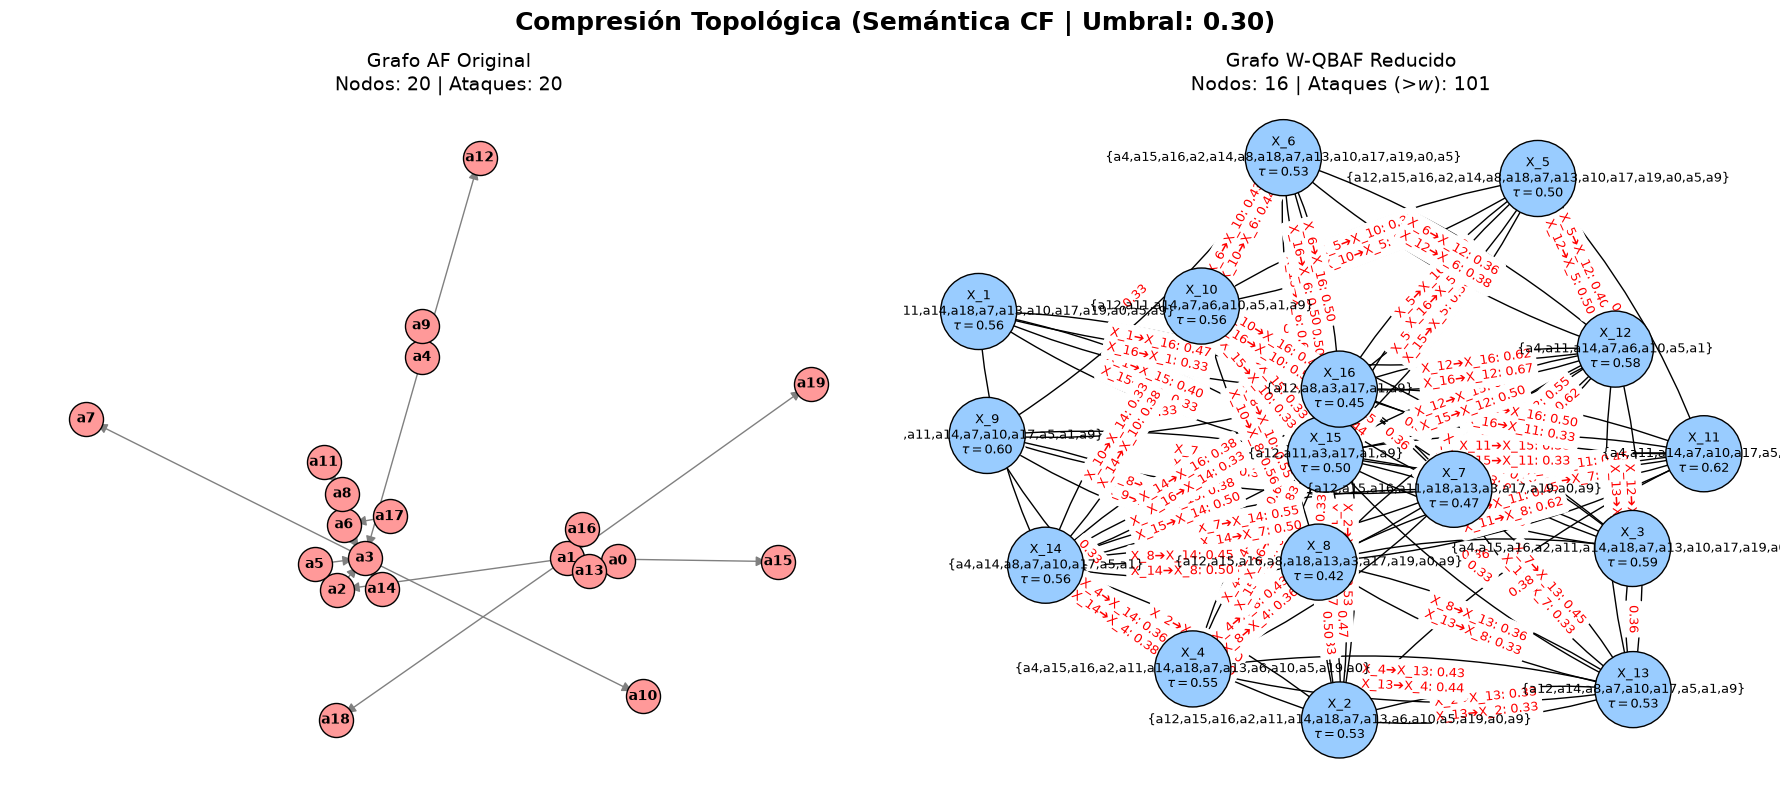

In [24]:
# ==========================================
# 3. EJECUCIÓN DESDE ARCHIVO (Instancias ER)
# ==========================================
import pygarg.dung.apx_parser

# Construimos la ruta hacia la carpeta donde tienes los grafos Erdős-Rényi
# (Ajusta la ruta si tu notebook está en otro nivel de carpetas)
carpeta_er = ruta_actual / "instances" / "BA"
archivo_elegido = carpeta_er / "BA-numArg20-pbCycle0-0.apx"

if archivo_elegido.exists():
    print(f"Cargando instancia: {archivo_elegido.name}...")
    
    # 1. Parseamos el archivo .apx
    args_archivo, atts_archivo = pygarg.dung.apx_parser.parse(str(archivo_elegido))
    
    # 2. Lanzamos la visualización (con Semántica Completa y Umbral Dinámico)
    visualizar_reduccion_simplicial(args_archivo, atts_archivo, semantica='CF', umbral_manual=None)
else:
    print(f"Error: No se ha encontrado el archivo en la ruta {archivo_elegido}")
    print("Comprueba que el notebook está en la carpeta correcta respecto a 'instances'.")

Cargando instancia: BA-numArg20-pbCycle0-0.apx...


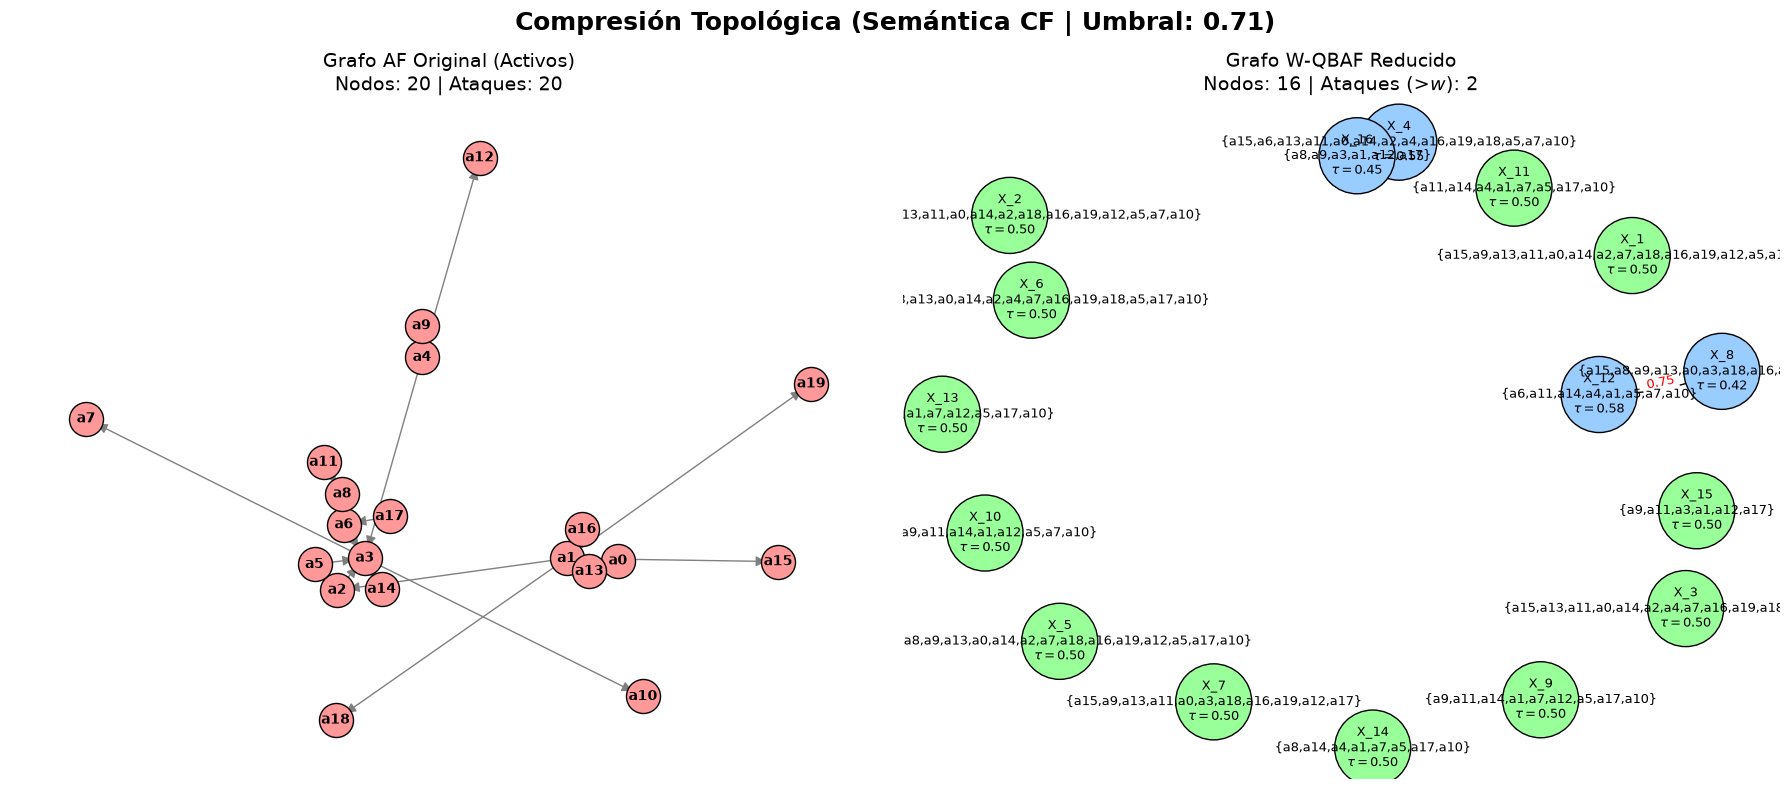

In [1]:
import sys
import statistics
import networkx as nx
import matplotlib.pyplot as plt
from pathlib import Path

# Configuración de rutas para importar pygarg
ruta_actual = Path().resolve()
ruta_src = ruta_actual.parent / "src"
if str(ruta_src) not in sys.path:
    sys.path.append(str(ruta_src))

import pygarg.dung.solver
import pygarg.dung.apx_parser

def visualizar_reduccion_simplicial(args, atts, semantica='CO', umbral_manual=None):
    """
    Calcula la reducción W-QBAF purgando los argumentos aislados del AF original
    y renderiza una comparativa visual corrigiendo etiquetas mutuas.
    """
    # ==========================================
    # 0. PRE-PROCESAMIENTO: ELIMINAR NODOS AISLADOS
    # ==========================================
    argumentos_activos = set()
    for atacante, atacado in atts:
        argumentos_activos.add(atacante)
        argumentos_activos.add(atacado)
        
    args_limpios = [arg for arg in args if arg in argumentos_activos]
    
    if not args_limpios:
        print("El grafo no contiene ataques (todos los argumentos estaban aislados).")
        return

    # ==========================================
    # 1. LÓGICA DE REDUCCIÓN (Semántica y Maximalidad)
    # ==========================================
    # Pasamos args_limpios en lugar de la lista en bruto
    extensiones = list(pygarg.dung.solver.extension_enumeration(args_limpios, atts, semantica))
    
    # Descartar conjunto vacío y aplicar filtro estricto de maximalidad
    facetas_todas = [set(ext) for ext in extensiones if ext]
    facetas = [f for f in facetas_todas if not any(f < g for g in facetas_todas if f != g)]
    
    # Ordenar para mantener consistencia visual
    facetas_ordenadas = sorted([sorted(list(f)) for f in facetas])
    A_star_inicial = {f"X_{i+1}": set(faceta) for i, faceta in enumerate(facetas_ordenadas)}
    
    # Usar args_limpios para los diccionarios de adyacencia
    out_adj = {arg: set() for arg in args_limpios}
    in_adj = {arg: set() for arg in args_limpios}
    for atacante, atacado in atts:
        out_adj[atacante].add(atacado)
        in_adj[atacado].add(atacante)

    pesos_brutos = {}
    
    # Calcular pesos teóricos w(X,Y)
    for id_X, X in A_star_inicial.items():
        for id_Y, Y in A_star_inicial.items():
            if id_X == id_Y: continue
            
            atacantes = {x for x in X if not out_adj[x].isdisjoint(Y)}
            if atacantes:
                pesos_brutos[(id_X, id_Y)] = len(atacantes) / len(X)
                
    # Determinar y aplicar el umbral
    umbral_aplicado = umbral_manual if umbral_manual is not None else (statistics.mean(pesos_brutos.values()) if pesos_brutos else 0.0)
    
    R_star_filtrado = []
    pesos_w_finales = {}
    nodos_conectados = set()
    
    for (origen, destino), peso in pesos_brutos.items():
        if peso >= umbral_aplicado:
            R_star_filtrado.append((origen, destino))
            pesos_w_finales[(origen, destino)] = peso
            nodos_conectados.add(origen)
            nodos_conectados.add(destino)
            
    A_star_conectados = {id_X: X for id_X, X in A_star_inicial.items() if id_X in nodos_conectados}
    A_star_aislados = {id_X: X for id_X, X in A_star_inicial.items() if id_X not in nodos_conectados}
    
    valoraciones_tau = {}
    for id_X, X in A_star_conectados.items():
        r_out = sum(len([tgt for tgt in out_adj[x] if tgt not in X]) for x in X)
        r_in = sum(len([src for src in in_adj[x] if src not in X]) for x in X)
        valoraciones_tau[id_X] = 0.5 if (r_out + r_in) == 0 else 0.5 * (((r_out - r_in) / (r_out + r_in)) + 1.0)
        
    for id_X in A_star_aislados.keys():
        valoraciones_tau[id_X] = 0.5

    # ==========================================
    # 2. VISUALIZACIÓN GRÁFICA (Matplotlib + NetworkX)
    # ==========================================
    fig, axes = plt.subplots(1, 2, figsize=(18, 8))
    fig.suptitle(f"Compresión Topológica (Semántica {semantica} | Umbral: {umbral_aplicado:.2f})", fontsize=18, fontweight='bold')

    # --- GRAFO 1: AF ORIGINAL (Limpio de aislados) ---
    G_orig = nx.DiGraph()
    G_orig.add_nodes_from(args_limpios)
    G_orig.add_edges_from(atts)
    
    pos_orig = nx.spring_layout(G_orig, seed=42)
    
    nx.draw_networkx_nodes(G_orig, pos_orig, ax=axes[0], node_color='#ff9999', node_size=600, edgecolors='black')
    nx.draw_networkx_labels(G_orig, pos_orig, ax=axes[0], font_size=10, font_weight='bold')
    nx.draw_networkx_edges(G_orig, pos_orig, ax=axes[0], arrowstyle='-|>', arrowsize=15, edge_color='gray')
    axes[0].set_title(f"Grafo AF Original (Activos)\nNodos: {len(args_limpios)} | Ataques: {len(atts)}", fontsize=14)
    axes[0].axis('off')

    # --- GRAFO 2: W-QBAF REDUCIDO ---
    G_red = nx.DiGraph()
    
    etiquetas_red = {}
    colores_nodos = []
    
    for id_X, X in A_star_conectados.items():
        G_red.add_node(id_X)
        args_str = "{" + ",".join(X) + "}"
        etiquetas_red[id_X] = f"{id_X}\n{args_str}\n$\\tau={valoraciones_tau[id_X]:.2f}$"
        colores_nodos.append('#99ccff') 
        
    for id_X, X in A_star_aislados.items():
        G_red.add_node(id_X)
        args_str = "{" + ",".join(X) + "}"
        etiquetas_red[id_X] = f"{id_X}\n{args_str}\n$\\tau={valoraciones_tau[id_X]:.2f}$"
        colores_nodos.append('#99ff99') 

    G_red.add_edges_from(R_star_filtrado)
    
    if len(G_red.nodes) > 0:
        pos_red = nx.spring_layout(G_red, seed=42)
        nx.draw_networkx_nodes(G_red, pos_red, ax=axes[1], node_color=colores_nodos, node_size=3000, edgecolors='black')
        nx.draw_networkx_labels(G_red, pos_red, labels=etiquetas_red, ax=axes[1], font_size=9)
        nx.draw_networkx_edges(G_red, pos_red, ax=axes[1], arrowstyle='-|>', arrowsize=20, edge_color='black', connectionstyle="arc3,rad=0.1")
        
        # Lógica para evitar superposición en ataques mutuos
        etiquetas_aristas = {}
        aristas_procesadas = set()
        
        for u, v in G_red.edges():
            if (u, v) in aristas_procesadas or (v, u) in aristas_procesadas:
                continue
                
            peso_ida = pesos_w_finales.get((u, v))
            peso_vuelta = pesos_w_finales.get((v, u))
            
            if peso_ida is not None and peso_vuelta is not None:
                etiquetas_aristas[(u, v)] = f"{u}➔{v}: {peso_ida:.2f}\n{v}➔{u}: {peso_vuelta:.2f}"
            else:
                etiquetas_aristas[(u, v)] = f"{peso_ida:.2f}"
                
            aristas_procesadas.add((u, v))
            aristas_procesadas.add((v, u))

        nx.draw_networkx_edge_labels(G_red, pos_red, edge_labels=etiquetas_aristas, ax=axes[1], font_size=9, font_color='red')
    
    nodos_red = len(A_star_conectados) + len(A_star_aislados)
    axes[1].set_title(f"Grafo W-QBAF Reducido\nNodos: {nodos_red} | Ataques (>$w$): {len(R_star_filtrado)}", fontsize=14)
    axes[1].axis('off')

    plt.tight_layout()
    plt.show()

# ==========================================
# 3. EJECUCIÓN DESDE ARCHIVO (Instancias ER)
# ==========================================
carpeta_er = ruta_actual / "instances" / "BA"

# Cargar la instancia de tu captura
archivo_elegido = carpeta_er / "BA-numArg20-pbCycle0-0.apx"

if archivo_elegido.exists():
    print(f"Cargando instancia: {archivo_elegido.name}...")
    args_archivo, atts_archivo = pygarg.dung.apx_parser.parse(str(archivo_elegido))
    
    # Lanzamos la visualización
    visualizar_reduccion_simplicial(args_archivo, atts_archivo, semantica='CF', umbral_manual=0.71)
else:
    print(f"Error: No se ha encontrado el archivo {archivo_elegido}")

In [6]:
import sys
import statistics
import networkx as nx
import matplotlib.pyplot as plt
from pathlib import Path

# Configuración de rutas para importar pygarg
ruta_actual = Path().resolve()
ruta_src = ruta_actual.parent / "src"
if str(ruta_src) not in sys.path:
    sys.path.append(str(ruta_src))

import pygarg.dung.solver
import pygarg.dung.apx_parser

def visualizar_reduccion_simplicial(args, atts, semantica='CO', umbral_manual=None):
    """
    Calcula la reducción W-QBAF purgando los argumentos aislados del AF original.
    Los meta-argumentos que quedan aislados tras el umbral son descartados por completo.
    """
    # ==========================================
    # 0. PRE-PROCESAMIENTO: ELIMINAR NODOS AISLADOS DEL AF ORIGINAL
    # ==========================================
    argumentos_activos = set()
    for atacante, atacado in atts:
        argumentos_activos.add(atacante)
        argumentos_activos.add(atacado)
        
    args_limpios = [arg for arg in args if arg in argumentos_activos]
    
    if not args_limpios:
        print("El grafo no contiene ataques (todos los argumentos estaban aislados).")
        return

    # ==========================================
    # 1. LÓGICA DE REDUCCIÓN (Semántica y Maximalidad)
    # ==========================================
    extensiones = list(pygarg.dung.solver.extension_enumeration(args_limpios, atts, semantica))
    
    # Descartar conjunto vacío y aplicar filtro estricto de maximalidad
    facetas_todas = [set(ext) for ext in extensiones if ext]
    facetas = [f for f in facetas_todas if not any(f < g for g in facetas_todas if f != g)]
    
    facetas_ordenadas = sorted([sorted(list(f)) for f in facetas])
    A_star_inicial = {f"X_{i+1}": set(faceta) for i, faceta in enumerate(facetas_ordenadas)}
    
    out_adj = {arg: set() for arg in args_limpios}
    in_adj = {arg: set() for arg in args_limpios}
    for atacante, atacado in atts:
        out_adj[atacante].add(atacado)
        in_adj[atacado].add(atacante)

    pesos_brutos = {}
    
    # Calcular pesos teóricos w(X,Y)
    for id_X, X in A_star_inicial.items():
        for id_Y, Y in A_star_inicial.items():
            if id_X == id_Y: continue
            
            atacantes = {x for x in X if not out_adj[x].isdisjoint(Y)}
            if atacantes:
                pesos_brutos[(id_X, id_Y)] = len(atacantes) / len(X)
                
    # Determinar y aplicar el umbral
    umbral_aplicado = umbral_manual if umbral_manual is not None else (statistics.mean(pesos_brutos.values()) if pesos_brutos else 0.0)
    
    R_star_filtrado = []
    pesos_w_finales = {}
    nodos_conectados = set()
    
    for (origen, destino), peso in pesos_brutos.items():
        if peso >= umbral_aplicado:
            R_star_filtrado.append((origen, destino))
            pesos_w_finales[(origen, destino)] = peso
            nodos_conectados.add(origen)
            nodos_conectados.add(destino)
            
    # Solo conservamos los meta-argumentos que tienen al menos una conexión.
    # Los aislados se ignoran y eliminan del análisis.
    A_star_conectados = {id_X: X for id_X, X in A_star_inicial.items() if id_X in nodos_conectados}
    
    valoraciones_tau = {}
    for id_X, X in A_star_conectados.items():
        r_out = sum(len([tgt for tgt in out_adj[x] if tgt not in X]) for x in X)
        r_in = sum(len([src for src in in_adj[x] if src not in X]) for x in X)
        valoraciones_tau[id_X] = 0.5 if (r_out + r_in) == 0 else 0.5 * (((r_out - r_in) / (r_out + r_in)) + 1.0)

    # ==========================================
    # 2. VISUALIZACIÓN GRÁFICA (Matplotlib + NetworkX)
    # ==========================================
    fig, axes = plt.subplots(1, 2, figsize=(18, 8))
    fig.suptitle(f"Compresión Topológica (Semántica {semantica} | Umbral: {umbral_aplicado:.2f})", fontsize=18, fontweight='bold')

    # --- GRAFO 1: AF ORIGINAL (Limpio de aislados) ---
    G_orig = nx.DiGraph()
    G_orig.add_nodes_from(args_limpios)
    G_orig.add_edges_from(atts)
    
    pos_orig = nx.spring_layout(G_orig, seed=42)
    
    nx.draw_networkx_nodes(G_orig, pos_orig, ax=axes[0], node_color='#ff9999', node_size=600, edgecolors='black')
    nx.draw_networkx_labels(G_orig, pos_orig, ax=axes[0], font_size=10, font_weight='bold')
    nx.draw_networkx_edges(G_orig, pos_orig, ax=axes[0], arrowstyle='-|>', arrowsize=15, edge_color='gray')
    axes[0].set_title(f"Grafo AF Original (Activos)\nNodos: {len(args_limpios)} | Ataques: {len(atts)}", fontsize=14)
    axes[0].axis('off')

    # --- GRAFO 2: W-QBAF REDUCIDO (Solo conectados) ---
    G_red = nx.DiGraph()
    
    etiquetas_red = {}
    colores_nodos = []
    
    for id_X, X in A_star_conectados.items():
        G_red.add_node(id_X)
        args_str = "{" + ",".join(X) + "}"
        etiquetas_red[id_X] = f"{id_X}\n{args_str}\n$\\tau={valoraciones_tau[id_X]:.2f}$"
        colores_nodos.append('#99ccff') 

    G_red.add_edges_from(R_star_filtrado)
    
    if len(G_red.nodes) > 0:
        pos_red = nx.spring_layout(G_red, seed=42)
        nx.draw_networkx_nodes(G_red, pos_red, ax=axes[1], node_color=colores_nodos, node_size=3000, edgecolors='black')
        nx.draw_networkx_labels(G_red, pos_red, labels=etiquetas_red, ax=axes[1], font_size=9)
        nx.draw_networkx_edges(G_red, pos_red, ax=axes[1], arrowstyle='-|>', arrowsize=20, edge_color='black', connectionstyle="arc3,rad=0.1")
        
        etiquetas_aristas = {}
        aristas_procesadas = set()
        
        for u, v in G_red.edges():
            if (u, v) in aristas_procesadas or (v, u) in aristas_procesadas:
                continue
                
            peso_ida = pesos_w_finales.get((u, v))
            peso_vuelta = pesos_w_finales.get((v, u))
            
            if peso_ida is not None and peso_vuelta is not None:
                etiquetas_aristas[(u, v)] = f"{u}➔{v}: {peso_ida:.2f}\n{v}➔{u}: {peso_vuelta:.2f}"
            else:
                etiquetas_aristas[(u, v)] = f"{peso_ida:.2f}"
                
            aristas_procesadas.add((u, v))
            aristas_procesadas.add((v, u))

        nx.draw_networkx_edge_labels(G_red, pos_red, edge_labels=etiquetas_aristas, ax=axes[1], font_size=9, font_color='red')
    
    nodos_red = len(A_star_conectados)
    axes[1].set_title(f"Grafo W-QBAF Reducido\nNodos: {nodos_red} | Ataques (>$w$): {len(R_star_filtrado)}", fontsize=14)
    axes[1].axis('off')

    plt.tight_layout()
    plt.show()

# ==========================================
# 3. EJECUCIÓN DESDE ARCHIVO (Instancias BA)
# ==========================================
carpeta_ba = ruta_actual / "instances" / "BA"

# Cargar la instancia de tu captura
archivo_elegido = carpeta_ba / "BA-numArg20-pbCycle0-0.apx"

if archivo_elegido.exists():
    print(f"Cargando instancia: {archivo_elegido.name}...")
    args_archivo, atts_archivo = pygarg.dung.apx_parser.parse(str(archivo_elegido))
    
    # Lanzamos la visualización
    visualizar_reduccion_simplicial(args_archivo, atts_archivo, semantica='C0', umbral_manual=None)
else:
    print(f"Error: No se ha encontrado el archivo {archivo_elegido}")

Cargando instancia: BA-numArg20-pbCycle0-0.apx...


SystemExit: No SAT encoding for the semantics : C0